In [ ]:
# ============================================================
# HW1 - Question 2: Diabetes Neural Network
# Personal parameters and reproducibility setup
# ============================================================

# Personal parameters derived from the last four digits
# of the SJSU student ID.
SID4 = 1980

# SEED is used for dataset splitting and random initialization.
SEED = SID4

# Dataset subset starting index (not used directly in HW1).
SLICE = SID4 % 1000

# Determines the modified neural-network configuration.
HP_ID = SID4 % 6

# Focus-class parameters required by the standing requirements.
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Display all personal parameters.
print("SID4  =", SID4)
print("SEED  =", SEED)
print("SLICE =", SLICE)
print("HP_ID =", HP_ID)
print("CLS_A =", CLS_A)
print("CLS_B =", CLS_B)

SID4  = 1980
SEED  = 1980
SLICE = 980
HP_ID = 0
CLS_A = 0
CLS_B = 1


In [ ]:
# ============================================================
# Reproducibility Setup
# ============================================================

import random
import numpy as np
import torch
import tensorflow as tf

# Set all required random seeds using SEED = 1980.
# This makes the experiments reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python random seed:", SEED)
print("NumPy seed:", SEED)
print("PyTorch seed:", SEED)
print("TensorFlow seed:", SEED)

Python random seed: 1980
NumPy seed: 1980
PyTorch seed: 1980
TensorFlow seed: 1980


In [ ]:
# ============================================================
# Load and inspect the Diabetes dataset
# ============================================================

# Pandas is used to read and work with tabular data.
import pandas as pd

# Load the CSV file into a pandas DataFrame.
df = pd.read_csv("diabetes.csv")

# Display the dataset size: (number of rows, number of columns).
print("Dataset shape:", df.shape)

# Display the column names.
print("\nColumns:")
print(df.columns.tolist())

# Display the first 5 rows to understand the dataset structure.
df.head()

Dataset shape: (758, 9)

Columns:
['-0.294118', '0.487437', '0.180328', '-0.292929', '0', '0.00149028', '-0.53117', '-0.0333333', '0.1']


,-0.294118,0.487437,0.180328,-0.292929,0,0.00149028,-0.53117,-0.0333333,0.1
0,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
1,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
2,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
3,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0
4,-0.411765,0.165829,0.213115,0.000000,0.000000,-0.236960,-0.894962,-0.700000,1


In [ ]:
# ============================================================
# Load and inspect the Diabetes dataset
# ============================================================

# Pandas is used to read and work with tabular data.
import pandas as pd

# The CSV does not contain column headers, so header=None
# prevents the first data row from being treated as column names.
df = pd.read_csv("diabetes.csv", header=None)

# Display the number of rows and columns.
print("Dataset shape:", df.shape)

# Display the first 5 rows.
df.head()

Dataset shape: (759, 9)


,0,1,2,3,4,5,6,7,8
0,-0.294118,0.487437,0.180328,-0.292929,0.000000,0.001490,-0.531170,-0.033333,0
1,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
2,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
3,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
4,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0


In [ ]:
# ============================================================
# Assign meaningful column names
# ============================================================

# The dataset contains 8 input features and 1 target variable.
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# Assign the names to the DataFrame.
df.columns = column_names

# Display the first 5 rows with the new column names.
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,-0.294118,0.487437,0.180328,-0.292929,0.000000,0.001490,-0.531170,-0.033333,0
1,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
2,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
3,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
4,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0


In [ ]:
# ============================================================
# Check dataset information and data quality
# ============================================================

# Show data types and check whether any columns contain missing values.
print("Dataset information:")
df.info()

# Count missing (NaN) values in each column.
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicate rows.
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check the number of samples in each target class.
print("\nOutcome distribution:")
print(df["Outcome"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 759 entries, 0 to 758
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               759 non-null    float64
 1   Glucose                   759 non-null    float64
 2   BloodPressure             759 non-null    float64
 3   SkinThickness             759 non-null    float64
 4   Insulin                   759 non-null    float64
 5   BMI                       759 non-null    float64
 6   DiabetesPedigreeFunction  759 non-null    float64
 7   Age                       759 non-null    float64
 8   Outcome                   759 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 53.5 KB

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFuncti

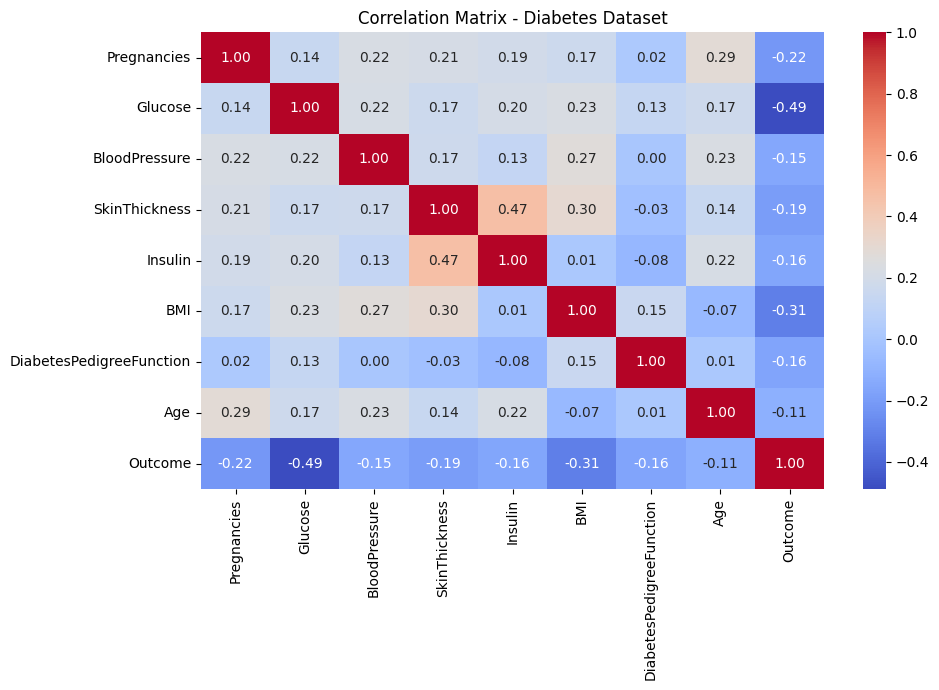

In [ ]:
# ============================================================
# Correlation Matrix
# ============================================================

# Matplotlib and Seaborn are used for data visualization.
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate pairwise correlations between all variables.
correlation_matrix = df.corr()

# Create the correlation heatmap.
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,       # Display correlation values inside each cell.
    fmt=".2f",        # Show values with two decimal places.
    cmap="coolwarm"
)

plt.title("Correlation Matrix - Diabetes Dataset")
plt.tight_layout()
plt.show()

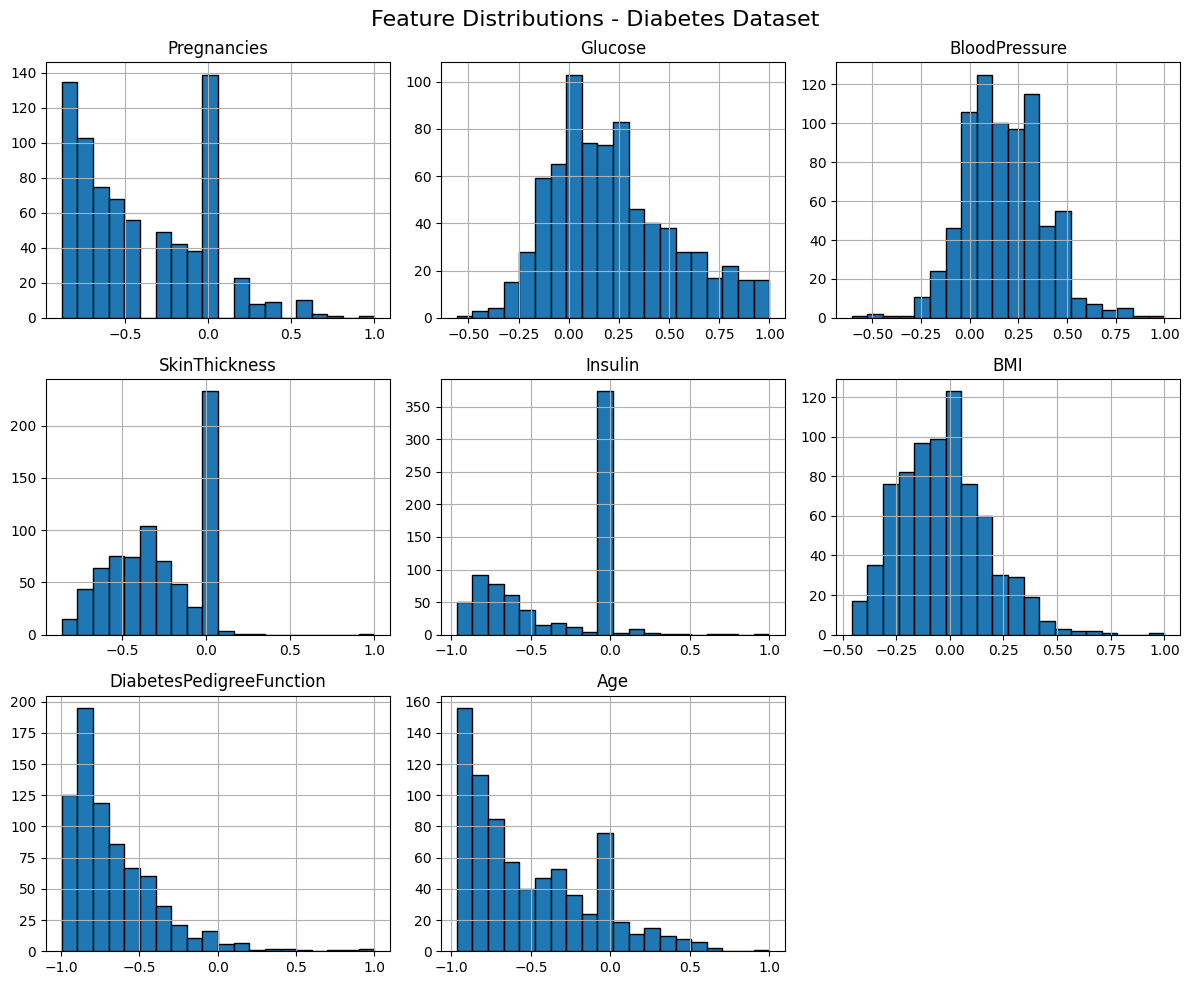

In [ ]:
# ============================================================
# Feature Distributions
# ============================================================

# Select only the 8 input features (exclude the Outcome target).
features = df.drop(columns=["Outcome"])

# Plot a histogram for each feature to understand
# how the feature values are distributed across the dataset.
features.hist(
    figsize=(12, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Feature Distributions - Diabetes Dataset", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Split the dataset into Train / Validation / Test sets
# ============================================================

from sklearn.model_selection import train_test_split

# Separate the 8 input features (X) from the target Outcome (y).
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# First split:
# 70% of the data is used for training.
# The remaining 30% is temporarily kept for validation + testing.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Second split:
# Divide the remaining 30% equally into 15% validation and 15% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

# Display the final split sizes.
print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Testing samples    :", len(X_test))

print("\nTotal samples:", len(X_train) + len(X_val) + len(X_test))

Training samples   : 531
Validation samples : 114
Testing samples    : 114

Total samples: 759


In [ ]:
# ============================================================
# Check feature ranges before neural-network training
# ============================================================

# Display the minimum and maximum value of every input feature.
# This helps verify whether the supplied dataset is already scaled.
feature_ranges = pd.DataFrame({
    "Minimum": X_train.min(),
    "Maximum": X_train.max()
})

print("Training feature ranges:")
display(feature_ranges)

Training feature ranges:


,Minimum,Maximum
Pregnancies,-0.882353,1.000000
Glucose,-0.557789,1.000000
BloodPressure,-0.606557,1.000000
SkinThickness,-0.858586,0.272727
Insulin,-0.966903,1.000000
BMI,-0.457526,1.000000
DiabetesPedigreeFunction,-0.994876,1.000000
Age,-0.966667,1.000000


In [ ]:
# ============================================================
# Convert the fixed dataset splits to NumPy arrays
# ============================================================

import numpy as np

# Convert feature data to float32.
# Neural-network frameworks work efficiently with float32 values.
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np   = X_val.to_numpy(dtype=np.float32)
X_test_np  = X_test.to_numpy(dtype=np.float32)

# Convert target labels to float32 for binary classification.
y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np   = y_val.to_numpy(dtype=np.float32)
y_test_np  = y_test.to_numpy(dtype=np.float32)

# Verify the shapes before building the neural networks.
print("X_train:", X_train_np.shape, "y_train:", y_train_np.shape)
print("X_val:  ", X_val_np.shape,   "y_val:  ", y_val_np.shape)
print("X_test: ", X_test_np.shape,  "y_test: ", y_test_np.shape)

X_train: (531, 8) y_train: (531,)
X_val:   (114, 8) y_val:   (114,)
X_test:  (114, 8) y_test:  (114,)


In [ ]:
# ============================================================
# PyTorch Baseline Model
# Architecture: [64, 32]
# Learning rate: 0.001
# Epochs: 30
# ============================================================

import torch
import torch.nn as nn

# Define the baseline feedforward neural network.
class PyTorchBaseline(nn.Module):
    def __init__(self):
        super().__init__()

        # 8 input features -> 64 hidden neurons
        self.fc1 = nn.Linear(8, 64)

        # 64 hidden neurons -> 32 hidden neurons
        self.fc2 = nn.Linear(64, 32)

        # 32 hidden neurons -> 1 output for binary classification
        self.fc3 = nn.Linear(32, 1)

        # ReLU activation is used after hidden layers.
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        # No sigmoid here because BCEWithLogitsLoss
        # applies sigmoid internally in a numerically stable way.
        return x

# Create the baseline model.
baseline_model = PyTorchBaseline()

# Display the model architecture.
print(baseline_model)

PyTorchBaseline(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)


In [ ]:
# ============================================================
# Train PyTorch Baseline Model
# Seed: 1980
# Learning rate: 0.001
# Epochs: 30
# ============================================================

import torch.optim as optim

# Set the training seed for reproducibility.
torch.manual_seed(SEED)

# Convert NumPy arrays to PyTorch tensors.
X_train_t = torch.tensor(X_train_np)
y_train_t = torch.tensor(y_train_np).reshape(-1, 1)

X_val_t = torch.tensor(X_val_np)
y_val_t = torch.tensor(y_val_np).reshape(-1, 1)

# Create a fresh baseline model.
baseline_model = PyTorchBaseline()

# Binary classification loss.
criterion = nn.BCEWithLogitsLoss()

# Adam optimizer with the assignment-required learning rate.
optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

# Store losses so we can plot them later.
train_losses = []
val_losses = []

# Train for the required 30 epochs.
for epoch in range(30):

    # ----- Training -----
    baseline_model.train()

    optimizer.zero_grad()

    train_logits = baseline_model(X_train_t)
    train_loss = criterion(train_logits, y_train_t)

    train_loss.backward()
    optimizer.step()

    # ----- Validation -----
    baseline_model.eval()

    with torch.no_grad():
        val_logits = baseline_model(X_val_t)
        val_loss = criterion(val_logits, y_val_t)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    # Display progress every 5 epochs.
    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:2d}/30 | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

Epoch  5/30 | Train Loss: 0.6823 | Validation Loss: 0.6788
Epoch 10/30 | Train Loss: 0.6693 | Validation Loss: 0.6662
Epoch 15/30 | Train Loss: 0.6574 | Validation Loss: 0.6548
Epoch 20/30 | Train Loss: 0.6456 | Validation Loss: 0.6437
Epoch 25/30 | Train Loss: 0.6331 | Validation Loss: 0.6320
Epoch 30/30 | Train Loss: 0.6198 | Validation Loss: 0.6200


In [ ]:
# ============================================================
# Evaluate PyTorch Baseline on the Test Set
# ============================================================

# Convert test data to PyTorch tensors.
X_test_t = torch.tensor(X_test_np)
y_test_t = torch.tensor(y_test_np).reshape(-1, 1)

# Switch model to evaluation mode.
baseline_model.eval()

with torch.no_grad():
    # Get raw output logits from the model.
    test_logits = baseline_model(X_test_t)

    # Convert logits to probabilities using sigmoid.
    test_probs = torch.sigmoid(test_logits)

    # Convert probabilities into class predictions:
    # probability >= 0.5 -> class 1
    # probability < 0.5  -> class 0
    test_preds = (test_probs >= 0.5).float()

    # Calculate classification accuracy.
    test_accuracy = (test_preds == y_test_t).float().mean().item()

print(f"PyTorch Baseline Test Accuracy: {test_accuracy:.4f}")

PyTorch Baseline Test Accuracy: 0.6491


In [ ]:
# ============================================================
# PyTorch Modified Model
# HP_ID = 0
# Architecture: [32]
# Learning rate: 0.001
# Epochs: 30
# ============================================================

class PyTorchModified(nn.Module):
    def __init__(self):
        super().__init__()

        # 8 input features -> 32 hidden neurons
        self.fc1 = nn.Linear(8, 32)

        # 32 hidden neurons -> 1 output neuron
        self.fc2 = nn.Linear(32, 1)

        # ReLU activation for the hidden layer
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        # No sigmoid here because BCEWithLogitsLoss
        # will apply it internally.
        return x

# Create the modified model.
modified_model = PyTorchModified()

# Display the architecture.
print(modified_model)

PyTorchModified(
  (fc1): Linear(in_features=8, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)


In [ ]:
# ============================================================
# Train PyTorch Modified Model
# HP_ID = 0
# Seed: 1980
# Architecture: [32]
# Learning rate: 0.001
# Epochs: 30
# ============================================================

# Set the training seed for reproducibility.
torch.manual_seed(SEED)

# Create a fresh modified model.
modified_model = PyTorchModified()

# Binary classification loss.
criterion = nn.BCEWithLogitsLoss()

# Adam optimizer with the required learning rate.
optimizer = optim.Adam(
    modified_model.parameters(),
    lr=0.001
)

# Store losses so we can compare with the baseline later.
modified_train_losses = []
modified_val_losses = []

# Train for 30 epochs.
for epoch in range(30):

    # ----- Training -----
    modified_model.train()

    optimizer.zero_grad()

    train_logits = modified_model(X_train_t)
    train_loss = criterion(train_logits, y_train_t)

    train_loss.backward()
    optimizer.step()

    # ----- Validation -----
    modified_model.eval()

    with torch.no_grad():
        val_logits = modified_model(X_val_t)
        val_loss = criterion(val_logits, y_val_t)

    modified_train_losses.append(train_loss.item())
    modified_val_losses.append(val_loss.item())

    # Display progress every 5 epochs.
    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:2d}/30 | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

Epoch  5/30 | Train Loss: 0.6684 | Validation Loss: 0.6676
Epoch 10/30 | Train Loss: 0.6595 | Validation Loss: 0.6591
Epoch 15/30 | Train Loss: 0.6509 | Validation Loss: 0.6511
Epoch 20/30 | Train Loss: 0.6429 | Validation Loss: 0.6435
Epoch 25/30 | Train Loss: 0.6352 | Validation Loss: 0.6365
Epoch 30/30 | Train Loss: 0.6280 | Validation Loss: 0.6300


In [ ]:
# ============================================================
# Evaluate PyTorch Modified Model on the Test Set
# ============================================================

# Switch the modified model to evaluation mode.
modified_model.eval()

with torch.no_grad():
    # Get raw logits for the test set.
    test_logits = modified_model(X_test_t)

    # Convert logits to probabilities.
    test_probs = torch.sigmoid(test_logits)

    # Convert probabilities to binary predictions.
    test_preds = (test_probs >= 0.5).float()

    # Calculate test accuracy.
    modified_test_accuracy = (
        (test_preds == y_test_t).float().mean().item()
    )

print(
    f"PyTorch Modified Test Accuracy: "
    f"{modified_test_accuracy:.4f}"
)

PyTorch Modified Test Accuracy: 0.6491


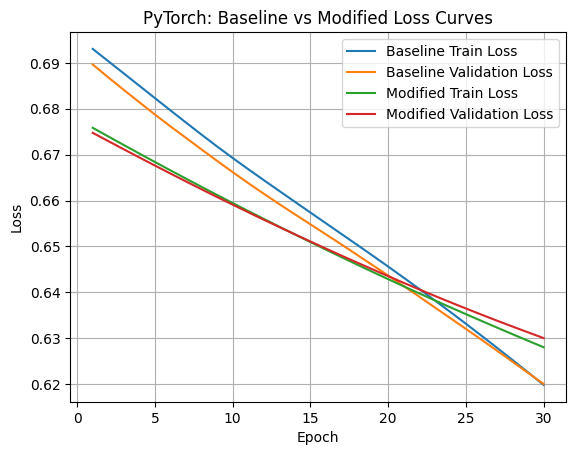

In [ ]:
# ============================================================
# PyTorch Loss Curves
# Baseline vs Modified Model
# ============================================================

import matplotlib.pyplot as plt

epochs = range(1, 31)

# Plot baseline losses.
plt.plot(epochs, train_losses, label="Baseline Train Loss")
plt.plot(epochs, val_losses, label="Baseline Validation Loss")

# Plot modified-model losses.
plt.plot(epochs, modified_train_losses, label="Modified Train Loss")
plt.plot(epochs, modified_val_losses, label="Modified Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PyTorch: Baseline vs Modified Loss Curves")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# PyTorch 3-Seed Experiment
# Seeds: 1980, 1981, 1982
# Compare Baseline [64,32] vs Modified [32]
# ============================================================

def train_and_test_pytorch(model_class, seed):

    # Set the training seed so model initialization is reproducible.
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Create a fresh model for this run.
    model = model_class()

    # Binary classification loss and Adam optimizer.
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Train for the required 30 epochs.
    for epoch in range(30):
        model.train()

        optimizer.zero_grad()
        logits = model(X_train_t)
        loss = criterion(logits, y_train_t)

        loss.backward()
        optimizer.step()

    # Evaluate the trained model on the fixed test set.
    model.eval()

    with torch.no_grad():
        test_logits = model(X_test_t)
        test_probs = torch.sigmoid(test_logits)
        test_preds = (test_probs >= 0.5).float()

        accuracy = (
            (test_preds == y_test_t).float().mean().item()
        )

    return accuracy


# Required training seeds.
training_seeds = [SEED, SEED + 1, SEED + 2]

baseline_accuracies = []
modified_accuracies = []

# Train both models using each seed.
for seed in training_seeds:

    baseline_acc = train_and_test_pytorch(
        PyTorchBaseline, seed
    )

    modified_acc = train_and_test_pytorch(
        PyTorchModified, seed
    )

    baseline_accuracies.append(baseline_acc)
    modified_accuracies.append(modified_acc)

    print(
        f"Seed {seed} | "
        f"Baseline: {baseline_acc:.4f} | "
        f"Modified: {modified_acc:.4f}"
    )


# Calculate mean and standard deviation across the three runs.
print("\nPyTorch Results")

print(
    f"Baseline: {np.mean(baseline_accuracies):.4f} "
    f"± {np.std(baseline_accuracies):.4f}"
)

print(
    f"Modified: {np.mean(modified_accuracies):.4f} "
    f"± {np.std(modified_accuracies):.4f}"
)

Seed 1980 | Baseline: 0.6491 | Modified: 0.6491
Seed 1981 | Baseline: 0.6491 | Modified: 0.7018
Seed 1982 | Baseline: 0.6491 | Modified: 0.6491

PyTorch Results
Baseline: 0.6491 ± 0.0000
Modified: 0.6667 ± 0.0248


In [ ]:
# ============================================================
# TensorFlow Baseline Model
# Architecture: [64, 32]
# Learning rate: 0.001
# Epochs: 30
# ============================================================

import tensorflow as tf

# Set the seed for reproducible model initialization.
tf.keras.utils.set_random_seed(SEED)

# Build the baseline feedforward neural network.
tf_baseline_model = tf.keras.Sequential([

    # Input contains the 8 diabetes features.
    tf.keras.layers.Input(shape=(8,)),

    # First hidden layer with 64 neurons and ReLU activation.
    tf.keras.layers.Dense(64, activation="relu"),

    # Second hidden layer with 32 neurons and ReLU activation.
    tf.keras.layers.Dense(32, activation="relu"),

    # One output neuron with sigmoid for binary classification.
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Configure the model using Adam with the required learning rate.
tf_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture and number of parameters.
tf_baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# Train TensorFlow Baseline Model
# Seed: 1980
# Learning rate: 0.001
# Epochs: 30
# ============================================================

# Reset TensorFlow/Keras state.
tf.keras.backend.clear_session()

# Set the training seed for reproducibility.
tf.keras.utils.set_random_seed(SEED)

# Rebuild a fresh baseline model.
tf_baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model.
tf_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train the model and save training history for later plots.
tf_baseline_history = tf_baseline_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_val_np, y_val_np),
    epochs=30,
    batch_size=32,
    verbose=0
)

# Print loss every 5 epochs.
for epoch in [4, 9, 14, 19, 24, 29]:
    print(
        f"Epoch {epoch+1:2d}/30 | "
        f"Train Loss: {tf_baseline_history.history['loss'][epoch]:.4f} | "
        f"Validation Loss: {tf_baseline_history.history['val_loss'][epoch]:.4f}"
    )

Epoch  5/30 | Train Loss: 0.5104 | Validation Loss: 0.5318
Epoch 10/30 | Train Loss: 0.4496 | Validation Loss: 0.5249
Epoch 15/30 | Train Loss: 0.4352 | Validation Loss: 0.5408
Epoch 20/30 | Train Loss: 0.4269 | Validation Loss: 0.5488
Epoch 25/30 | Train Loss: 0.4198 | Validation Loss: 0.5534
Epoch 30/30 | Train Loss: 0.4134 | Validation Loss: 0.5555


In [ ]:
# ============================================================
# Evaluate TensorFlow Baseline on the Test Set
# ============================================================

# Evaluate the trained model on the fixed test set.
test_loss, test_accuracy_tf = tf_baseline_model.evaluate(
    X_test_np,
    y_test_np,
    verbose=0
)

print(f"TensorFlow Baseline Test Accuracy: {test_accuracy_tf:.4f}")
print(f"TensorFlow Baseline Test Loss: {test_loss:.4f}")

TensorFlow Baseline Test Accuracy: 0.7895
TensorFlow Baseline Test Loss: 0.4666


In [ ]:
# ============================================================
# TensorFlow Modified Model
# HP_ID = 0
# Architecture: [32]
# Learning rate: 0.001
# Epochs: 30
# ============================================================

# Reset Keras state before creating a new model.
tf.keras.backend.clear_session()

# Set the seed for reproducibility.
tf.keras.utils.set_random_seed(SEED)

# Build the modified model.
tf_modified_model = tf.keras.Sequential([

    # Input contains the 8 diabetes features.
    tf.keras.layers.Input(shape=(8,)),

    # Single hidden layer with 32 neurons.
    tf.keras.layers.Dense(32, activation="relu"),

    # One output neuron for binary classification.
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Configure the model.
tf_modified_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture.
tf_modified_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# Train TensorFlow Modified Model
# Seed: 1980
# Architecture: [32]
# Learning rate: 0.001
# Epochs: 30
# ============================================================

# Reset Keras state.
tf.keras.backend.clear_session()

# Set the training seed for reproducibility.
tf.keras.utils.set_random_seed(SEED)

# Rebuild a fresh modified model.
tf_modified_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model.
tf_modified_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train and save the loss history for later plotting.
tf_modified_history = tf_modified_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_val_np, y_val_np),
    epochs=30,
    batch_size=32,
    verbose=0
)

# Print loss every 5 epochs.
for epoch in [4, 9, 14, 19, 24, 29]:
    print(
        f"Epoch {epoch+1:2d}/30 | "
        f"Train Loss: {tf_modified_history.history['loss'][epoch]:.4f} | "
        f"Validation Loss: {tf_modified_history.history['val_loss'][epoch]:.4f}"
    )

Epoch  5/30 | Train Loss: 0.6231 | Validation Loss: 0.6213
Epoch 10/30 | Train Loss: 0.5443 | Validation Loss: 0.5646
Epoch 15/30 | Train Loss: 0.4980 | Validation Loss: 0.5420
Epoch 20/30 | Train Loss: 0.4737 | Validation Loss: 0.5377
Epoch 25/30 | Train Loss: 0.4611 | Validation Loss: 0.5407
Epoch 30/30 | Train Loss: 0.4538 | Validation Loss: 0.5457


In [ ]:
# ============================================================
# Evaluate TensorFlow Modified Model on the Test Set
# ============================================================

# Evaluate the modified model on the same fixed test set.
modified_test_loss_tf, modified_test_accuracy_tf = tf_modified_model.evaluate(
    X_test_np,
    y_test_np,
    verbose=0
)

print(f"TensorFlow Modified Test Accuracy: {modified_test_accuracy_tf:.4f}")
print(f"TensorFlow Modified Test Loss: {modified_test_loss_tf:.4f}")

TensorFlow Modified Test Accuracy: 0.7982
TensorFlow Modified Test Loss: 0.4828


In [ ]:
# ============================================================
# TensorFlow 3-Seed Experiment
# Seeds: 1980, 1981, 1982
# Compare Baseline [64,32] vs Modified [32]
# ============================================================

def train_and_test_tensorflow(model_type, seed):

    # Clear previous TensorFlow/Keras models from memory.
    tf.keras.backend.clear_session()

    # Set TensorFlow, NumPy, and Python-related seeds.
    tf.keras.utils.set_random_seed(seed)

    # Build the required model architecture.
    if model_type == "baseline":

        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(8,)),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

    else:

        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(8,)),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

    # Compile using the same optimizer and learning rate.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Train for the required 30 epochs.
    model.fit(
        X_train_np,
        y_train_np,
        epochs=30,
        batch_size=32,
        verbose=0
    )

    # Evaluate on the same fixed test set.
    _, test_accuracy = model.evaluate(
        X_test_np,
        y_test_np,
        verbose=0
    )

    return test_accuracy


tf_baseline_accuracies = []
tf_modified_accuracies = []

# Run both models using the required three training seeds.
for seed in training_seeds:

    baseline_acc = train_and_test_tensorflow(
        "baseline",
        seed
    )

    modified_acc = train_and_test_tensorflow(
        "modified",
        seed
    )

    tf_baseline_accuracies.append(baseline_acc)
    tf_modified_accuracies.append(modified_acc)

    print(
        f"Seed {seed} | "
        f"Baseline: {baseline_acc:.4f} | "
        f"Modified: {modified_acc:.4f}"
    )

# Calculate mean and standard deviation across the three runs.
print("\nTensorFlow Results")

print(
    f"Baseline: {np.mean(tf_baseline_accuracies):.4f} "
    f"± {np.std(tf_baseline_accuracies):.4f}"
)

print(
    f"Modified: {np.mean(tf_modified_accuracies):.4f} "
    f"± {np.std(tf_modified_accuracies):.4f}"
)

Seed 1980 | Baseline: 0.7895 | Modified: 0.7982
Seed 1981 | Baseline: 0.7807 | Modified: 0.7982
Seed 1982 | Baseline: 0.7719 | Modified: 0.7982

TensorFlow Results
Baseline: 0.7807 ± 0.0072
Modified: 0.7982 ± 0.0000


In [ ]:
# ============================================================
# TensorFlow 3-Seed Experiment
# Seeds: 1980, 1981, 1982
# Compare Baseline [64,32] vs Modified [32]
# ============================================================

def train_and_test_tensorflow(model_type, seed):

    # Clear previous TensorFlow/Keras models from memory.
    tf.keras.backend.clear_session()

    # Set TensorFlow, NumPy, and Python-related seeds.
    tf.keras.utils.set_random_seed(seed)

    # Build the required model architecture.
    if model_type == "baseline":

        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(8,)),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

    else:

        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(8,)),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

    # Compile using the same optimizer and learning rate.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Train for the required 30 epochs.
    model.fit(
        X_train_np,
        y_train_np,
        epochs=30,
        batch_size=32,
        verbose=0
    )

    # Evaluate on the same fixed test set.
    _, test_accuracy = model.evaluate(
        X_test_np,
        y_test_np,
        verbose=0
    )

    return test_accuracy


tf_baseline_accuracies = []
tf_modified_accuracies = []

# Run both models using the required three training seeds.
for seed in training_seeds:

    baseline_acc = train_and_test_tensorflow(
        "baseline",
        seed
    )

    modified_acc = train_and_test_tensorflow(
        "modified",
        seed
    )

    tf_baseline_accuracies.append(baseline_acc)
    tf_modified_accuracies.append(modified_acc)

    print(
        f"Seed {seed} | "
        f"Baseline: {baseline_acc:.4f} | "
        f"Modified: {modified_acc:.4f}"
    )

# Calculate mean and standard deviation across the three runs.
print("\nTensorFlow Results")

print(
    f"Baseline: {np.mean(tf_baseline_accuracies):.4f} "
    f"± {np.std(tf_baseline_accuracies):.4f}"
)

print(
    f"Modified: {np.mean(tf_modified_accuracies):.4f} "
    f"± {np.std(tf_modified_accuracies):.4f}"
)

Seed 1980 | Baseline: 0.7895 | Modified: 0.7982
Seed 1981 | Baseline: 0.7807 | Modified: 0.7982
Seed 1982 | Baseline: 0.7719 | Modified: 0.7982

TensorFlow Results
Baseline: 0.7807 ± 0.0072
Modified: 0.7982 ± 0.0000


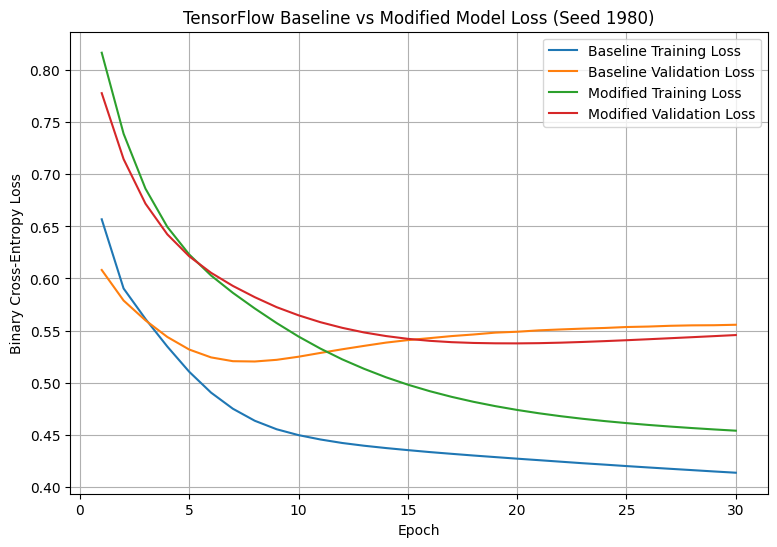

In [ ]:
# ============================================================
# TensorFlow Training and Validation Loss Curves
# Seed: 1980
# Compare Baseline [64,32] vs Modified [32]
# ============================================================

import matplotlib.pyplot as plt

# Epoch numbers from 1 to 30.
epochs = range(1, 31)

# Create one figure containing all four loss curves.
plt.figure(figsize=(9, 6))

# Baseline training and validation loss.
plt.plot(
    epochs,
    tf_baseline_history.history["loss"],
    label="Baseline Training Loss"
)

plt.plot(
    epochs,
    tf_baseline_history.history["val_loss"],
    label="Baseline Validation Loss"
)

# Modified model training and validation loss.
plt.plot(
    epochs,
    tf_modified_history.history["loss"],
    label="Modified Training Loss"
)

plt.plot(
    epochs,
    tf_modified_history.history["val_loss"],
    label="Modified Validation Loss"
)

# Add labels and title.
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("TensorFlow Baseline vs Modified Model Loss (Seed 1980)")

# Show legend and grid for readability.
plt.legend()
plt.grid(True)

# Display the graph.
plt.show()

TensorFlow Loss Curve Interpretation:
For the baseline model, training loss continuously decreases while validation loss begins increasing after approximately 7–8 epochs, indicating overfitting. The modified model also shows some overfitting near the later epochs, but the gap between training and validation loss develops more gradually. Overall, the modified model shows slightly better generalization, which is also reflected in its higher mean test accuracy across the three training seeds.

In [ ]:
# ============================================================
# Final Q2 Model Comparison
# Mean ± Standard Deviation Across 3 Training Seeds
# Seeds: 1980, 1981, 1982
# ============================================================

import pandas as pd
import numpy as np

# Create a summary table using the accuracies collected
# from the three PyTorch and TensorFlow training runs.
results_table = pd.DataFrame({
    "Framework": [
        "PyTorch",
        "PyTorch",
        "TensorFlow",
        "TensorFlow"
    ],

    "Model": [
        "Baseline [64, 32]",
        "Modified [32]",
        "Baseline [64, 32]",
        "Modified [32]"
    ],

    "Mean Test Accuracy": [
        np.mean(baseline_accuracies),
        np.mean(modified_accuracies),
        np.mean(tf_baseline_accuracies),
        np.mean(tf_modified_accuracies)
    ],

    "Std Test Accuracy": [
        np.std(baseline_accuracies),
        np.std(modified_accuracies),
        np.std(tf_baseline_accuracies),
        np.std(tf_modified_accuracies)
    ]
})

# Round the values to four decimal places for clear reporting.
results_table["Mean Test Accuracy"] = (
    results_table["Mean Test Accuracy"].round(4)
)

results_table["Std Test Accuracy"] = (
    results_table["Std Test Accuracy"].round(4)
)

# Display the final comparison table.
results_table

,Framework,Model,Mean Test Accuracy,Std Test Accuracy
0,PyTorch,"Baseline [64, 32]",0.6491,0.0000
1,PyTorch,Modified [32],0.6667,0.0248
2,TensorFlow,"Baseline [64, 32]",0.7807,0.0072
3,TensorFlow,Modified [32],0.7982,0.0000


Final Model Comparison:
The modified architecture for HP_ID = 0 uses one hidden layer with 32 neurons, a learning rate of 0.001, and 30 training epochs. In PyTorch, the modified model achieved a mean test accuracy of 0.6667 ± 0.0248, compared with 0.6491 ± 0.0000 for the baseline. In TensorFlow, the modified model achieved 0.7982 ± 0.0000, compared with 0.7807 ± 0.0072 for the baseline. Therefore, the modified [32] architecture achieved higher mean test accuracy than the baseline [64, 32] architecture in both frameworks. The loss curves indicate overfitting in the TensorFlow baseline and milder late-stage overfitting in the modified TensorFlow model.